# Hot-wire noise at the qubit plane, from the known gain

**Definitions** (all referred to the qubit plane, the reference plane of G)

- $T_\mathrm{sys}$: noise temperature of the whole system
- $T_N^\mathrm{HE}$: noise temperature of the hot wire at the qubit plane
- $T_\mathrm{add}$: noise temperature added by the chain after the qubit plane (HEMT, cables, SA)

**Relations**

$$T_\mathrm{sys}(V) = T_N^\mathrm{HE}(V) + T_\mathrm{add} = \frac{P(V)}{k_B\,B_\mathrm{ENBW}\,G}$$

$P$ is the noise power the SA reads, $B_\mathrm{ENBW}$ the equivalent noise bandwidth of the RBW filter
(113.2 kHz at RBW 100 kHz, `enbw_rbw100khz.ipynb`), and $G$ the gain from the qubit plane to the SA, measured
separately (VNA S21 + qubit power calibration).

At $V = 0$ the wire is at the fridge temperature $T_0$, which is much below the quantum noise
($T_0 = 12$ mK $\ll hf/2k_B = 134$ mK at 5.576 GHz), so the hot wire gives only the zero-point noise

$$T_N^\mathrm{HE}(0) = \frac{hf}{2k_B}\coth\frac{hf}{2k_BT_0} \approx \frac{hf}{2k_B}$$

$$T_\mathrm{add} = T_\mathrm{sys}(0) - T_N^\mathrm{HE}(0) = \frac{P(0)}{k_B\,B_\mathrm{ENBW}\,G} - \frac{hf}{2k_B}$$

and at any bias

$$T_N^\mathrm{HE}(V) = T_\mathrm{sys}(V) - T_\mathrm{add}$$

$T_N^\mathrm{HE}(V)$ is what the TWPA Y factor uses as its known source temperatures, also listed in photons
($k_BT_N^\mathrm{HE}/hf$).

**Fit.** The points of all runs are put together and fitted with the paper's hot-electron model (see *Fit*), which
gives $T_\mathrm{add}$ and a smooth $T_N^\mathrm{HE}(V)$ from all points instead of the single $V = 0$ point.

**Measurement settings.** SA zero span, RBW 100 kHz, VBW 3 MHz, average detector, power averaging, sweep ≥ 1 s:
the SA reads the noise power with no correction (checked 2026-10-20).

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

kB = 1.380649e-23
h = 6.62607015e-34

## Parameters

In [2]:
DATA_FILES = ["y_factor_0_1V.json"]
G_DB = 53.5              # system gain, qubit plane -> SA reading, TWPA off, from the VNA
ENBW_HZ = 113.2e3        # RBW 100 kHz, enbw_rbw100khz.ipynb
CSV_POINTS = "hotwire-qubit-plane-points.csv"
CSV_FIT = "hotwire-qubit-plane-fit.csv"
FIT_GRID_V = np.round(np.arange(-0.1, 0.1 + 1e-9, 0.001), 6)   # biases for the fitted table

## Data

In [3]:
G = 10 ** (G_DB / 10)
V, T_sys, src = [], [], []
for name in DATA_FILES:
    with open(name) as fh:
        d = json.load(fh)
    V.append(np.array(d["bias_v"]))
    T_sys.append(np.array(d["power_w"]) / (kB * ENBW_HZ * G))
    src += [name] * len(d["bias_v"])
    T0, f = d["fridge_temperature_k"], d["frequency_hz"]
    print(f"{name}: {len(d['bias_v'])} points, {min(d['bias_v']):g}..{max(d['bias_v']):g} V")
V, T_sys, src = np.concatenate(V), np.concatenate(T_sys), np.array(src)
T_half = h * f / (2 * kB)            # hf/2k_B: half-photon noise temperature

y_factor_0_1V.json: 101 points, -0.1..0.1 V


## Fit

**Model**, from the bias setting to the qubit plane (N. Bergeal *et al.*, Appl. Phys. Lett. **100**, 203507 (2012)):

1. Voltage across the wire: $V_w = k_V\,(V - V_0)$
2. Effective electron temperature of the wire (paper Eq. 2):
   $$T^\mathrm{eff} = \frac{T_0}{2}\Big[1 + \Big(\nu + \frac1\nu\Big)\arctan\nu\Big], \qquad
   \nu = \frac{\sqrt3}{2\pi}\frac{eV_w}{k_BT_0}$$
3. Noise the wire emits at $f$ (paper Eq. 3): $T_N^\mathrm{wire} = \frac{hf}{2k_B}\coth\frac{hf}{2k_BT^\mathrm{eff}}$
4. At the qubit plane, a fraction $\eta$ of it arrives and the rest is replaced by the zero point:
   $T_N^\mathrm{HE} = \eta\,T_N^\mathrm{wire} + (1 - \eta)\,\frac{hf}{2k_B}$
5. What the SA sees: $T_\mathrm{sys} = T_N^\mathrm{HE} + T_\mathrm{add}$

**Fit parameters**

- $k_V$: wire voltage per volt of 33220A setting (the bias circuit's divider). The knee, where $T^\mathrm{eff}$
  passes $hf/2k_B$, sets it: the known frequency calibrates the voltage scale.
- $\eta$: transmission from the wire to the qubit plane, i.e. a loss of $-10\log_{10}\eta$ dB between them.
- $V_0$: the setting at which the wire is at 0 V.
- $T_\mathrm{add}$: noise added by the chain after the qubit plane.

In [4]:
e = 1.602176634e-19

def T_eff(Vw):
    """Bergeal Eq. 2: effective temperature of the wire at voltage Vw (V) across it."""
    nu = np.maximum(np.sqrt(3) / (2 * np.pi) * e * np.abs(Vw) / (kB * T0), 1e-9)
    return T0 / 2 * (1 + (nu + 1 / nu) * np.arctan(nu))

def TN_model(V, kV_mV, V0_mV, eta):
    """T_N^HE at the qubit plane for the 33220A setting V (V); k_V in mV/V, V0 in mV."""
    Vw = kV_mV * 1e-3 * (V - V0_mV * 1e-3)              # step 1
    TN_wire = T_half / np.tanh(T_half / T_eff(Vw))       # steps 2-3
    return eta * TN_wire + (1 - eta) * T_half            # step 4

def residuals(p):
    kV_mV, V0_mV, eta, T_add = p
    return T_sys - T_add - TN_model(V, kV_mV, V0_mV, eta)   # step 5

sol = least_squares(residuals, [7.0, 0.0, 0.9, T_sys[np.argmin(np.abs(V))] - T_half])
kV_mV, V0_mV, eta, T_add = sol.x
for n, v in zip(["k_V (mV/V)", "V0 (mV)", "eta", "T_add (K)"], sol.x):
    print(f"{n:12s} {v:9.4f}")
print(f"loss wire -> qubit plane = {-10*np.log10(eta):.2f} dB")
TN = T_sys - T_add                                       # T_N^HE of every point

k_V (mV/V)      7.6084
V0 (mV)         0.0091
eta             0.8335
T_add (K)       7.7180
loss wire -> qubit plane = 0.79 dB


## Plots

$T_N^\mathrm{HE} = T_\mathrm{sys} - T_\mathrm{add}$ for every point and the fit; bottom: around zero bias.

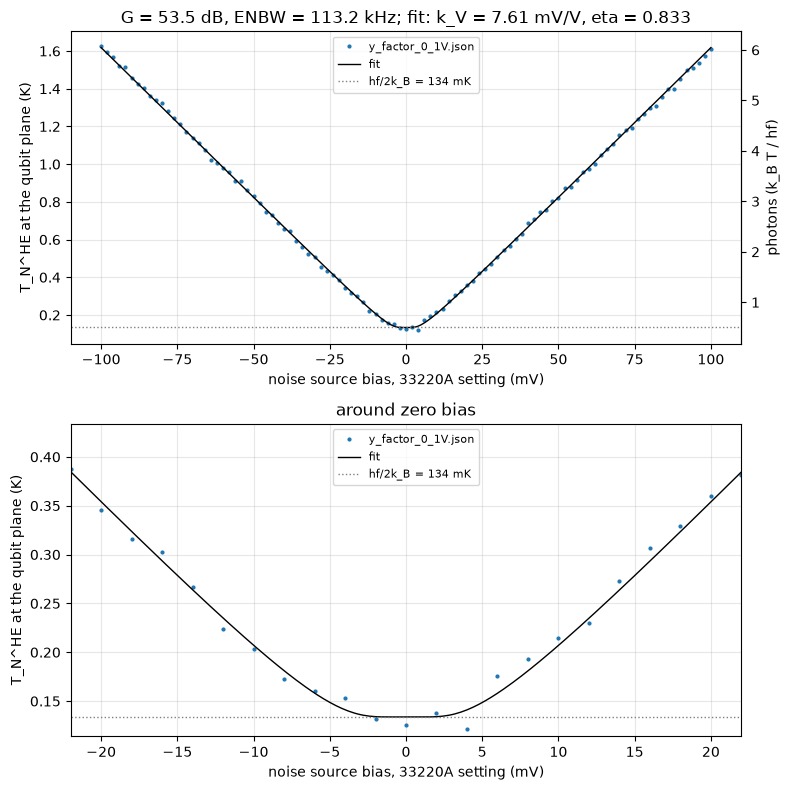

In [5]:
Vm = np.linspace(V.min(), V.max(), 1001)
fig, ax = plt.subplots(2, 1, figsize=(8, 8))
for a_ in ax:
    for i, name in enumerate(DATA_FILES):
        m = src == name
        a_.plot(V[m] * 1e3, TN[m], ".", color=f"C{i}", ms=4, label=name)
    a_.plot(Vm * 1e3, TN_model(Vm, kV_mV, V0_mV, eta), "k", lw=1, label="fit")
    a_.axhline(T_half, color="0.5", ls=":", lw=1, label=f"hf/2k_B = {T_half*1e3:.0f} mK")
    a_.set(xlabel="noise source bias, 33220A setting (mV)", ylabel="T_N^HE at the qubit plane (K)")
    a_.grid(alpha=0.3)
    a_.legend(fontsize=8)
ax[0].set(title=f"G = {G_DB} dB, ENBW = {ENBW_HZ/1e3:g} kHz; fit: k_V = {kV_mV:.2f} mV/V, eta = {eta:.3f}")
sec = ax[0].secondary_yaxis("right", functions=(lambda t: t / (2 * T_half), lambda n: n * 2 * T_half))
sec.set_ylabel("photons (k_B T / hf)")
ax[1].set(xlim=(-22, 22), ylim=(T_half - 0.02, T_half + 0.3), title="around zero bias")
fig.tight_layout()
plt.show()

## Values at the qubit plane

From the fit. Both CSV files are written: every measured point, and the fit on `FIT_GRID_V`.

In [6]:
TNg = TN_model(FIT_GRID_V, kV_mV, V0_mV, eta)
print(f"{'V (V)':>7} {'T_N^HE fit (K)':>15} {'photons':>8}")
for v, t in zip(FIT_GRID_V, TNg):
    if v >= 0 and (np.isclose(v * 1e3 % 10, 0) or v <= 0.01):
        print(f"{v:7.3f} {t:15.4f} {t/(2*T_half):8.3f}")

head = (f"# hot-wire noise at the qubit plane; G {G_DB} dB, ENBW {ENBW_HZ:g} Hz, f {f:g} Hz; "
        f"fit k_V {kV_mV:.4f} mV/V, V0 {V0_mV:.4f} mV, eta {eta:.4f}, T_add {T_add:.5f} K\n")
with open(CSV_POINTS, "w") as fh:
    fh.write(head + "file,bias_v,T_sys_k,T_N_HE_k,photons\n")
    for s, v, ts, tn in zip(src, V, T_sys, TN):
        fh.write(f"{s},{v:g},{ts:.6f},{tn:.6f},{tn/(2*T_half):.6f}\n")
with open(CSV_FIT, "w") as fh:
    fh.write(head + "bias_v,T_N_HE_fit_k,photons\n")
    for v, t in zip(FIT_GRID_V, TNg):
        fh.write(f"{v:g},{t:.6f},{t/(2*T_half):.6f}\n")
print("saved", CSV_POINTS, "and", CSV_FIT)

  V (V)  T_N^HE fit (K)  photons
  0.000          0.1338    0.500
  0.001          0.1338    0.500
  0.002          0.1341    0.501
  0.003          0.1361    0.509
  0.004          0.1411    0.527
  0.005          0.1486    0.555
  0.006          0.1581    0.591
  0.007          0.1690    0.632
  0.008          0.1810    0.676
  0.009          0.1937    0.724
  0.010          0.2070    0.774
  0.020          0.3539    1.322
  0.030          0.5089    1.902
  0.040          0.6660    2.489
  0.050          0.8240    3.079
  0.060          0.9825    3.671
  0.070          1.1412    4.264
  0.080          1.3001    4.858
  0.090          1.4590    5.452
  0.100          1.6180    6.046
saved hotwire-qubit-plane-points.csv and hotwire-qubit-plane-fit.csv
